# Week 6 & 7 Coding Tutorial: From Descriptive Statistics to A/B Testing
**Data Science: Foundations to Applications (SCD-4XX)** · Dept. of Smart Computing · Fall 2026

This 40-minute guided tutorial turns the key ideas from **Week 6 (Descriptive Statistics & Probability)** and **Week 7 (Inference & Hypothesis Testing)** into code you can run, change, and break.

| Part | Topic | Slides | Minutes |
|---|---|---|---|
| 0 | Setup | – | 2 |
| 1 | Central tendency & dispersion | Wk 6 · S1 | 6 |
| 2 | Normal, Binomial & Poisson distributions | Wk 6 · S1 | 6 |
| 3 | Conditional probability & Bayes' theorem | Wk 6 · S2 | 5 |
| 4 | Central Limit Theorem | Wk 6 · S3 | 4 |
| 5 | Confidence intervals | Wk 7 · S1 | 4 |
| 6 | t-test, chi-square, ANOVA | Wk 7 · S1–2 | 6 |
| 7 | A/B test end-to-end (with power analysis) | Wk 7 · S3 | 6 |
| 8 | Wrap-up checkpoint | – | 1 |

**How to use this notebook (Jupyter Notebook or JupyterLab):**
- Run a cell with `Shift + Enter`. Run cells **in order**, because later cells reuse earlier variables.
- Look for the **Your turn** boxes: change a number, re-run, and predict what will happen *before* you press Enter.
- If anything breaks: `Kernel → Restart Kernel and Run All Cells`.

## Part 0 · Setup  (2 min)
Everything below runs locally in Jupyter. You need `numpy`, `pandas`, `matplotlib`, `seaborn`, `scipy` and `statsmodels`.
If the import cell fails, install what's missing from your terminal (or Anaconda Prompt):

```
pip install numpy pandas matplotlib seaborn scipy statsmodels
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Power-analysis helpers (used in Part 7)
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

np.random.seed(42)   # reproducible randomness: everyone sees the same numbers

import scipy
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__)
print("Setup OK")

numpy 2.4.6 | pandas 3.0.3 | scipy 1.18.0
Setup OK


---
## Part 1 · Central Tendency & Dispersion  (6 min)
**Scenario:** an online shop has 200 days of revenue. Five of those days were big promotions. How do the different summary statistics react?

In [2]:
normal_days = np.random.normal(loc=1000, scale=150, size=195)
promo_days  = np.array([2800, 3200, 3500, 4100, 3900])       # five unusually big days

sales = pd.DataFrame({
    "daily_revenue": np.concatenate([normal_days, promo_days]).round(0),
    "top_category":  np.random.choice(["Electronics", "Clothing", "Home", "Toys"],
                                      size=200, p=[0.4, 0.3, 0.2, 0.1]),
})
sales.head()

,daily_revenue,top_category
0,1075.0,Clothing
1,979.0,Electronics
2,1097.0,Clothing
3,1228.0,Toys
4,965.0,Electronics


In [3]:
revenue = sales["daily_revenue"]

print("Mean:    ", round(revenue.mean(), 1))
print("Median:  ", revenue.median())
print("Mode of top_category:", sales["top_category"].mode()[0])   # mode is the one that works for categories

print("Variance:", round(revenue.var(), 1), " <- squared units (dollars²)")
print("Std Dev: ", round(revenue.std(), 1), " <- back in dollars")
print("Range:   ", revenue.max() - revenue.min())

q1, q3 = revenue.quantile([0.25, 0.75])
print("IQR:     ", q3 - q1)

Mean:     1057.5
Median:   1005.5
Mode of top_category: Electronics
Variance: 178529.2  <- squared units (dollars²)
Std Dev:  422.5  <- back in dollars
Range:    3493.0
IQR:      194.5


**Which numbers got "pulled" by the five promo days?** Let's compare all days against the days that are *not* flagged as outliers by the boxplot rule (beyond 1.5 × IQR from the box).

In [4]:
def summarize(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({"mean": s.mean(), "median": s.median(), "std": s.std(),
                      "range": s.max() - s.min(), "IQR": q3 - q1})

lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
typical = revenue[(revenue >= lower) & (revenue <= upper)]
print(f"Boxplot fences: [{lower:.0f}, {upper:.0f}]  ->  {len(revenue) - len(typical)} days flagged as outliers\n")

pd.DataFrame({"all days": summarize(revenue), "without outliers": summarize(typical)}).round(1)

Boxplot fences: [606, 1384]  ->  6 days flagged as outliers



,all days,without outliers
mean,1057.5,992.7
median,1005.5,997.0
std,422.5,137.7
range,3493.0,762.0
IQR,194.5,180.8


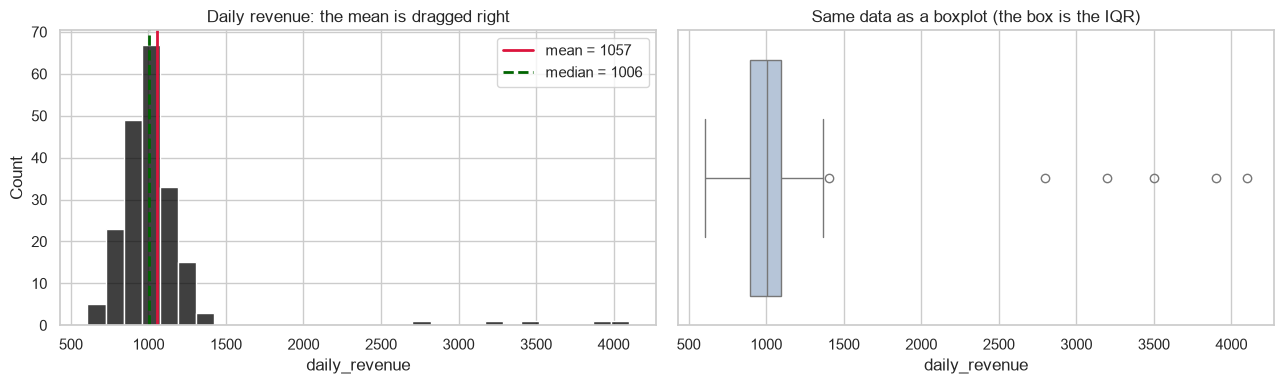

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(revenue, bins=30, ax=axes[0], color="black")
axes[0].axvline(revenue.mean(),   color="crimson", lw=2, label=f"mean = {revenue.mean():.0f}")
axes[0].axvline(revenue.median(), color="darkgreen", lw=2, ls="--", label=f"median = {revenue.median():.0f}")
axes[0].set_title("Daily revenue: the mean is dragged right")
axes[0].legend()

sns.boxplot(x=revenue, ax=axes[1], color="lightsteelblue")
axes[1].set_title("Same data as a boxplot (the box is the IQR)")
plt.tight_layout(); plt.show()

> **Your turn (1 min):** Mean and standard deviation both react strongly to outliers; median and IQR barely move. Which pair would you report to a manager if the promo days are *not* typical? Which pair if you are budgeting for *total* revenue?

promo days not typical - median and IQR
budgeting for total revenua - mean and standard deviation 

---
## Part 2 · Three Key Distributions  (6 min)
For each one we do the same two things: **simulate** with `np.random` (slide approach) and compute the **exact** probability with `scipy.stats`. They should agree.

### 2a · Normal: heights (mean 170 cm, std 8 cm)

within ±1 std devs:  simulated = 0.681   exact = 0.683
within ±2 std devs:  simulated = 0.953   exact = 0.954
within ±3 std devs:  simulated = 0.997   exact = 0.997

P(height > 185)  simulated: 0.0307 | exact: 0.0304


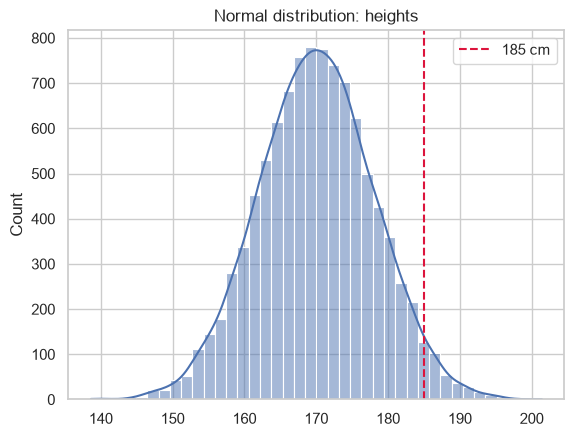

In [6]:
heights = np.random.normal(loc=170, scale=8, size=10_000)

# 68-95-99.7 rule: simulated vs exact
for k in (1, 2, 3):
    simulated = np.mean(np.abs(heights - 170) <= k * 8)
    exact = stats.norm.cdf(k) - stats.norm.cdf(-k)
    print(f"within ±{k} std devs:  simulated = {simulated:.3f}   exact = {exact:.3f}")

# A real question: what fraction of people are taller than 185 cm?
print("\nP(height > 185)  simulated:", np.mean(heights > 185).round(4),
      "| exact:", stats.norm.sf(185, loc=170, scale=8).round(4))

sns.histplot(heights, kde=True, bins=40)
plt.axvline(185, color="crimson", ls="--", label="185 cm"); plt.legend()
plt.title("Normal distribution: heights"); plt.show()

### 2b · Binomial: 20 visitors, each converts with probability 0.30
*Question from the slide:* what is the probability that **exactly 8** of 20 visitors convert?

P(exactly 8)   simulated: 0.0382 | exact (pmf): 0.1686
P(at least 8)  simulated: 0.9802 | exact (sf): 0.3828  <- sf(5) = P(X > 5) = P(X >= 6)


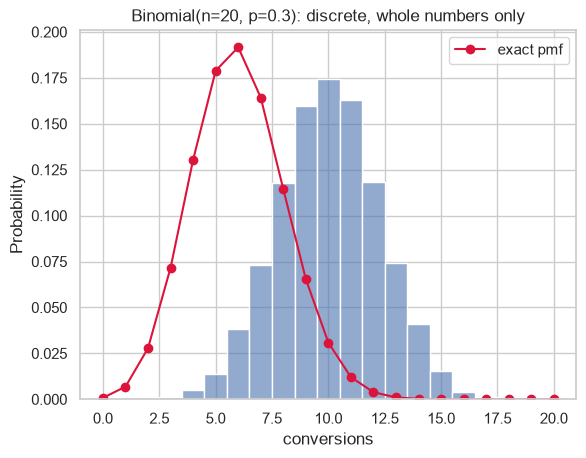

In [29]:
conversions = np.random.binomial(n=20, p=0.5, size=10_000)

print("P(exactly 8)   simulated:", np.mean(conversions == 6).round(4),
      "| exact (pmf):", stats.binom.pmf(6, n=20, p=0.25).round(4))
print("P(at least 8)  simulated:", np.mean(conversions >= 6).round(4),
      "| exact (sf):", stats.binom.sf(5, n=20, p=0.25).round(4), " <- sf(5) = P(X > 5) = P(X >= 6)")

sns.histplot(conversions, discrete=True, stat="probability", alpha=0.6)
x = np.arange(0, 21)
plt.plot(x, stats.binom.pmf(x, 20, 0.3), "o-", color="crimson", label="exact pmf")
plt.legend(); plt.title("Binomial(n=20, p=0.3): discrete, whole numbers only"); plt.xlabel("conversions"); plt.show()

### 2c · Poisson: a call center averaging 4 calls per minute
*Question from the slide:* what is the probability of **more than 8** calls in one minute?

P(more than 8)  simulated: 0.6703 | exact (sf): 0.0214
Mean and variance of a Poisson are both lambda: 10.03 10.22


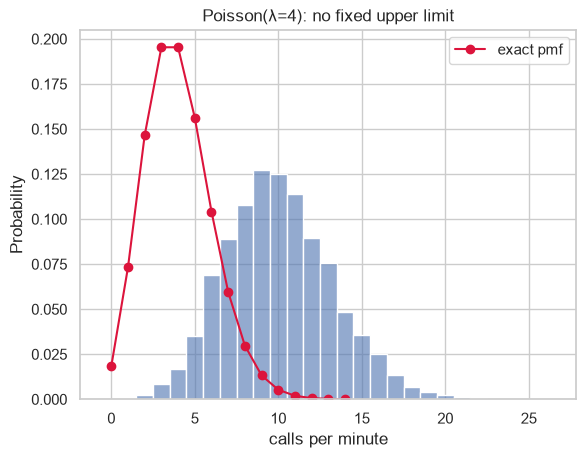

In [30]:
calls = np.random.poisson(lam=10, size=10_000)

print("P(more than 8)  simulated:", np.mean(calls > 8).round(4),
      "| exact (sf):", stats.poisson.sf(8, mu=4).round(4))
print("Mean and variance of a Poisson are both lambda:", calls.mean().round(2), calls.var().round(2))

sns.histplot(calls, discrete=True, stat="probability", alpha=0.6)
x = np.arange(0, 15)
plt.plot(x, stats.poisson.pmf(x, 4), "o-", color="crimson", label="exact pmf")
plt.legend(); plt.title("Poisson(λ=4): no fixed upper limit"); plt.xlabel("calls per minute"); plt.show()

> **Your turn (1 min):** Change `p=0.3` to `p=0.5` in 2b and `lam=4` to `lam=10` in 2c. Predict how each histogram moves *before* running. Which one gets visibly more symmetric?

Binomial gets visibly more symmetric 

---
## Part 3 · Conditional Probability & Bayes' Theorem  (5 min)
### 3a · Conditional probability from a table
Among 1,000 visitors: 300 are returning customers (150 convert) and 700 are new (70 convert).

In [9]:
visitors = pd.DataFrame({"Converted": [150, 70], "Not converted": [150, 630]},
                        index=["Returning", "New"])
display(visitors)

total = visitors.values.sum()
p_convert           = visitors["Converted"].sum() / total
p_returning         = visitors.loc["Returning"].sum() / total
p_convert_and_ret   = visitors.loc["Returning", "Converted"] / total

p_convert_given_returning = p_convert_and_ret / p_returning      # P(A|B) = P(A and B) / P(B)

print(f"P(convert)               = {p_convert:.2f}")
print(f"P(convert | returning)   = {p_convert_given_returning:.2f}   <- knowing more changes the probability")

,Converted,Not converted
Returning,150,150
New,70,630


P(convert)               = 0.22
P(convert | returning)   = 0.50   <- knowing more changes the probability


### 3b · Bayes' theorem: the surprising medical test

In [10]:
def bayes_posterior(prevalence, sensitivity, specificity):
    # P(disease | positive test)
    p_pos_given_disease = sensitivity
    p_pos_given_healthy = 1 - specificity                       # false-positive rate
    p_positive = p_pos_given_disease * prevalence + p_pos_given_healthy * (1 - prevalence)
    return p_pos_given_disease * prevalence / p_positive

print("P(disease | positive) =", round(bayes_posterior(0.01, 0.95, 0.90), 4))

# Verify with a simulation of one million people
N = 1_000_000
has_disease = np.random.rand(N) < 0.01
positive = np.where(has_disease, np.random.rand(N) < 0.95, np.random.rand(N) < 0.10)
print("Simulated             =", has_disease[positive].mean().round(4),
      f"  ({positive.sum():,} positives, only {has_disease[positive].sum():,} truly sick)")

P(disease | positive) = 0.0876
Simulated             = 0.088   (108,503 positives, only 9,548 truly sick)


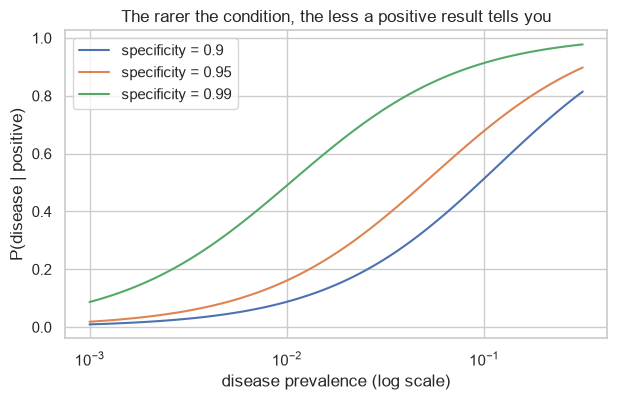

In [11]:
prevalence = np.logspace(-3, -0.5, 100)       # 0.1% to ~32%
plt.figure(figsize=(7, 4))
for spec in (0.90, 0.95, 0.99):
    plt.plot(prevalence, bayes_posterior(prevalence, 0.95, spec), label=f"specificity = {spec}")
plt.xscale("log"); plt.xlabel("disease prevalence (log scale)"); plt.ylabel("P(disease | positive)")
plt.title("The rarer the condition, the less a positive result tells you"); plt.legend(); plt.show()

**Quick rules check (from the Week 6 reference table):** the chance that *at least one* of 3 independent visitors converts (p = 0.3) uses the complement and multiplication rules.

In [12]:
rule = 1 - (1 - 0.3) ** 3
sim  = np.mean(np.random.binomial(3, 0.3, size=100_000) >= 1)
print(f"1 - (0.7)^3 = {rule:.4f}   simulated = {sim:.4f}")

1 - (0.7)^3 = 0.6570   simulated = 0.6596


---
## Part 4 · The Central Limit Theorem  (4 min)
The population below is **heavily skewed**: the opposite of a bell curve. What happens to the *means* of samples drawn from it as the sample size grows?

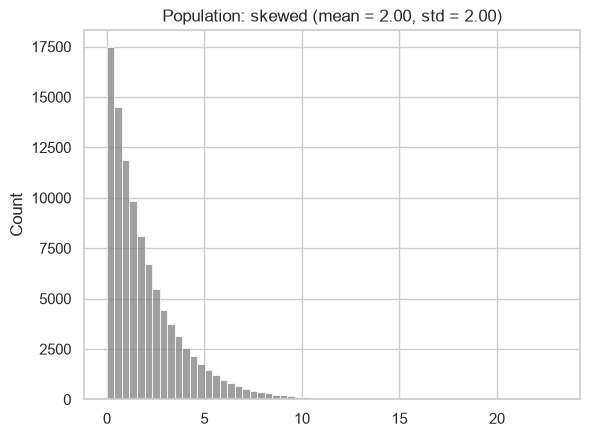

In [13]:
population = np.random.exponential(scale=2.0, size=100_000)
sns.histplot(population, bins=60, color="grey")
plt.title(f"Population: skewed (mean = {population.mean():.2f}, std = {population.std():.2f})"); plt.show()

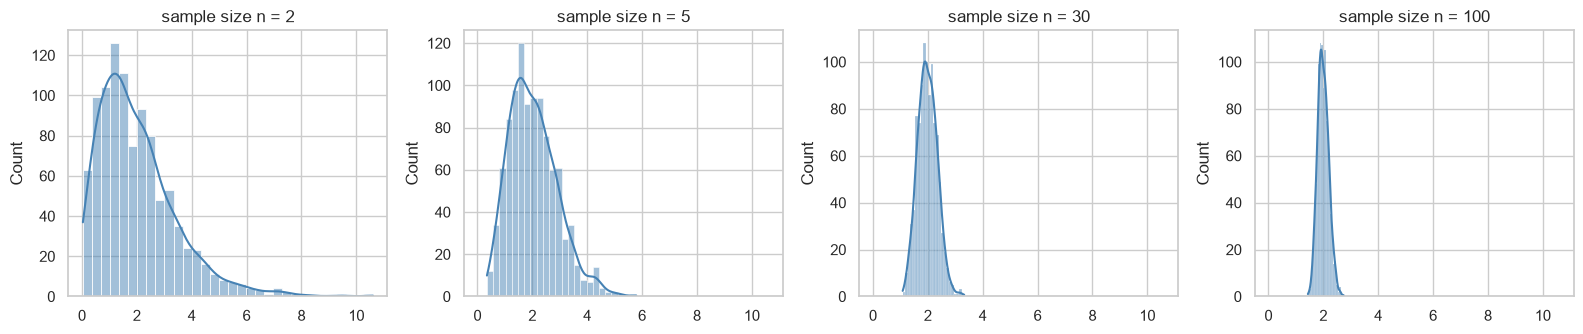

,mean of sample means,std of sample means,theory: σ/√n,skewness
n,,,,
2,2.000,1.412,1.411,1.439
5,2.036,0.872,0.892,0.695
30,1.988,0.350,0.364,0.248
100,1.997,0.199,0.200,0.303


In [14]:
sample_sizes = [2, 5, 30, 100]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharex=True)
rows = []
for ax, n in zip(axes, sample_sizes):
    sample_means = [np.random.choice(population, size=n).mean() for _ in range(1000)]
    sns.histplot(sample_means, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"sample size n = {n}")
    rows.append({"n": n,
                 "mean of sample means": np.mean(sample_means),
                 "std of sample means": np.std(sample_means),
                 "theory: σ/√n": population.std() / np.sqrt(n),
                 "skewness": stats.skew(sample_means)})
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3).set_index("n")

**What to notice:** (1) the histograms turn bell-shaped as *n* grows (skewness → 0); (2) the mean of the sample means stays near the population mean; (3) the spread of the sample means shrinks like **σ/√n**. That last quantity is the *standard error*, the key ingredient of confidence intervals.

> **Your turn:** change `scale=2.0` to a different value. Does the *shape* of the sample-mean histogram change? Does its *location*?

---
## Part 5 · Confidence Intervals  (4 min)
A confidence interval puts a margin of error around a point estimate, and it rests directly on the CLT.

In [15]:
sample = np.array([4.1, 3.9, 4.5, 4.0, 4.3, 3.8, 4.2, 4.4, 3.9, 4.1])

mean = sample.mean()
sem  = stats.sem(sample)                         # standard error of the mean = s / sqrt(n)
ci   = stats.t.interval(confidence=0.95, df=len(sample) - 1, loc=mean, scale=sem)
print(f"mean = {mean:.2f},  SEM = {sem:.3f},  95% CI = ({ci[0]:.2f}, {ci[1]:.2f})")

# The same thing "by hand": mean ± t* × SEM
t_star = stats.t.ppf(0.975, df=len(sample) - 1)
print(f"by hand: {mean - t_star * sem:.2f} to {mean + t_star * sem:.2f}   (t* = {t_star:.3f})")

mean = 4.12,  SEM = 0.073,  95% CI = (3.96, 4.28)
by hand: 3.96 to 4.28   (t* = 2.262)


**What does "95% confident" really mean?** Let's *repeat* the sampling process 1,000 times from a population whose true mean we know (50) and see how many intervals capture it.

94.7% of the 1000 intervals contain the true mean


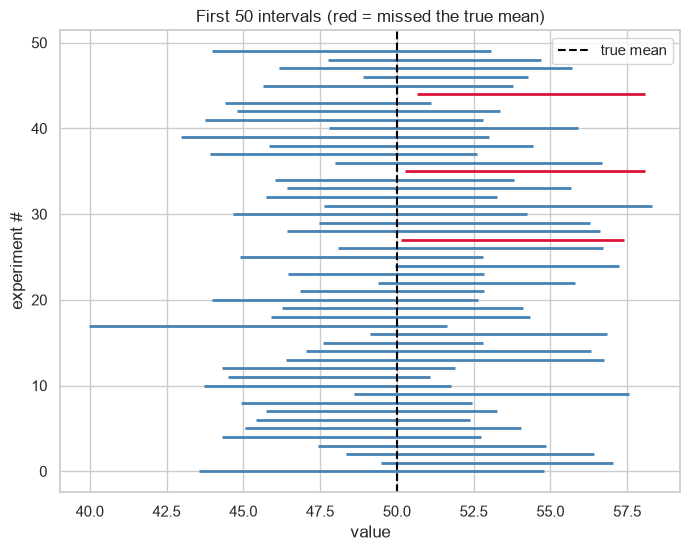

In [16]:
true_mu, true_sd, n, reps = 50, 10, 25, 1000
intervals = []
for _ in range(reps):
    s = np.random.normal(true_mu, true_sd, n)
    lo, hi = stats.t.interval(0.95, df=n - 1, loc=s.mean(), scale=stats.sem(s))
    intervals.append((lo, hi))

hits = np.array([lo <= true_mu <= hi for lo, hi in intervals])
print(f"{hits.mean():.1%} of the {reps} intervals contain the true mean")

plt.figure(figsize=(8, 6))
for i, (lo, hi) in enumerate(intervals[:50]):
    plt.hlines(i, lo, hi, color="steelblue" if hits[i] else "crimson", lw=2)
plt.axvline(true_mu, color="black", ls="--", label="true mean")
plt.title("First 50 intervals (red = missed the true mean)"); plt.xlabel("value"); plt.ylabel("experiment #")
plt.legend(); plt.show()

In [17]:
# More data -> narrower interval
for n in (10, 40, 160, 640):
    s = np.random.normal(50, 10, n)
    lo, hi = stats.t.interval(0.95, df=n - 1, loc=s.mean(), scale=stats.sem(s))
    print(f"n = {n:>3}:  CI width = {hi - lo:.2f}")

n =  10:  CI width = 14.87
n =  40:  CI width = 5.51
n = 160:  CI width = 3.09
n = 640:  CI width = 1.57


> **Common misreading (from the slides):** "there is a 95% chance the true mean is in *this* interval." Not quite: the 95% describes the **procedure**. About 95 of every 100 intervals built this way capture the truth, and the red lines above are the ones that don't.

---
## Part 6 · Choosing & Running the Right Test  (6 min)
Every test follows the same four steps: **(1)** state H₀ and H₁ → **(2)** choose α (we use 0.05) → **(3)** compute a test statistic → **(4)** compare the p-value with α.

In [18]:
alpha = 0.05

def decide(p, alpha=alpha):
    verdict = "REJECT H0" if p < alpha else "FAIL TO REJECT H0"
    return f"p = {p:.4f}  ->  {verdict} (at alpha = {alpha})"

### 6a · t-test (2 group means): landing page A vs B
H₀: both pages have the same true mean conversion rate. H₁: they differ (two-tailed).

In [19]:
page_a = [4.1, 3.9, 4.5, 4.0, 4.3, 3.8]
page_b = [5.0, 4.8, 5.3, 4.9, 5.1, 4.7]

t_stat, p_value = stats.ttest_ind(page_a, page_b)
print("t-statistic:", round(t_stat, 3))
print(decide(p_value))

# Safer default in practice: Welch's t-test does not assume equal variances
t_w, p_w = stats.ttest_ind(page_a, page_b, equal_var=False)
print("Welch version:", decide(p_w))

t-statistic: -6.269
p = 0.0001  ->  REJECT H0 (at alpha = 0.05)
Welch version: p = 0.0001  ->  REJECT H0 (at alpha = 0.05)


### 6b · Chi-square (two categorical variables): device type vs purchase

In [20]:
table = pd.DataFrame({"Purchased": [120, 90], "Not Purchased": [380, 410]},
                     index=["Mobile", "Desktop"])

chi2, p_value, dof, expected = stats.chi2_contingency(table)
print("Chi-square:", round(chi2, 3), "| dof:", dof)
print(decide(p_value))

print("\nObserved purchase rate:\n", (table["Purchased"] / table.sum(axis=1)).round(3).to_string())
print("\nExpected counts if device and purchase were independent:")
display(pd.DataFrame(expected, index=table.index, columns=table.columns).round(1))

Chi-square: 5.069 | dof: 1
p = 0.0244  ->  REJECT H0 (at alpha = 0.05)

Observed purchase rate:
 Mobile     0.24
Desktop    0.18

Expected counts if device and purchase were independent:


,Purchased,Not Purchased
Mobile,105.0,395.0
Desktop,105.0,395.0


### 6c · ANOVA (3+ group means): time-on-page for three layouts

In [21]:
layout_a = [45, 50, 48, 52, 47]
layout_b = [60, 58, 62, 59, 61]
layout_c = [44, 46, 43, 45, 47]

f_stat, p_value = stats.f_oneway(layout_a, layout_b, layout_c)
print("F-statistic:", round(f_stat, 2))
print(decide(p_value))

# ANOVA says THAT groups differ, not WHICH. Post-hoc test (Tukey HSD) finds the pairs:
print(stats.tukey_hsd(layout_a, layout_b, layout_c))

F-statistic: 75.43
p = 0.0000  ->  REJECT H0 (at alpha = 0.05)
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)    -11.600     0.000   -15.017    -8.183
 (0 - 2)      3.400     0.051    -0.017     6.817
 (1 - 0)     11.600     0.000     8.183    15.017
 (1 - 2)     15.000     0.000    11.583    18.417
 (2 - 0)     -3.400     0.051    -6.817     0.017
 (2 - 1)    -15.000     0.000   -18.417   -11.583



> **Your turn:** In 6c, shift `layout_c` upward by 10 (e.g. `[54, 56, 53, 55, 57]`) and re-run. What happens to the ANOVA result? Which pairs does Tukey now flag?

| Question | Test |
|---|---|
| Do 2 groups have different means? | t-test |
| Are 2 categorical variables related? | chi-square |
| Do 3+ groups have different means? | ANOVA (then post-hoc) |

---
## Part 7 · A/B Test, End to End  (6 min)
**Scenario:** Version A: 42 conversions out of 1,000 visitors (4.2%). Version B: 58 out of 1,000 (5.8%). Should we ship B?

**Step 1: hypotheses.** H₀: both versions have the same true conversion rate. H₁: they differ. α = 0.05, chosen *before* looking at results.

In [22]:
table = pd.DataFrame({"Converted": [42, 58], "Not Converted": [958, 942]},
                     index=["Version A", "Version B"])

chi2, p_yates, _, _ = stats.chi2_contingency(table)                       # default for 2x2: Yates continuity correction
_, p_plain, _, _    = stats.chi2_contingency(table, correction=False)    # uncorrected

print("p-value (default, continuity-corrected):", round(p_yates, 4))
print("p-value (uncorrected):                  ", round(p_plain, 4))
print(decide(p_yates))

p-value (default, continuity-corrected): 0.1238
p-value (uncorrected):                   0.1007
p = 0.1238  ->  FAIL TO REJECT H0 (at alpha = 0.05)


Surprised? A 1.6-point jump *looked* meaningful, yet the test says the data is **not** enough to rule out plain sampling noise. **Failing to reject H₀ is not the same as proving "no difference."** Let's quantify the uncertainty with a confidence interval for the difference.

In [23]:
conv_a, n_a, conv_b, n_b = 42, 1000, 58, 1000
p_a, p_b = conv_a / n_a, conv_b / n_b

diff = p_b - p_a
se   = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
lo, hi = diff - 1.96 * se, diff + 1.96 * se

print(f"Observed lift: {diff * 100:.2f} percentage points  ({diff / p_a:.0%} relative)")
print(f"95% CI for the difference: [{lo * 100:.2f}, {hi * 100:.2f}] percentage points")
print("The interval includes 0" if lo < 0 < hi else "The interval excludes 0")

Observed lift: 1.60 percentage points  (38% relative)
95% CI for the difference: [-0.31, 3.51] percentage points
The interval includes 0


**Step 2: was the test big enough?** Power analysis (done *before* launching a test) tells us how many users per group we need to detect a given lift with 80% power.

In [24]:
def n_per_group(p_base, p_new, power=0.8, alpha=0.05):
    effect = proportion_effectsize(p_new, p_base)             # Cohen's h
    return int(np.ceil(NormalIndPower().solve_power(effect_size=effect, alpha=alpha,
                                                    power=power, ratio=1.0)))

for base, new in [(0.042, 0.058), (0.040, 0.041), (0.040, 0.060)]:
    print(f"{base:.1%} -> {new:.1%}:  need ≈ {n_per_group(base, new):>9,} users per group")

4.2% -> 5.8%:  need ≈     2,895 users per group
4.0% -> 4.1%:  need ≈   609,987 users per group
4.0% -> 6.0%:  need ≈     1,846 users per group


**Step 3: communicate.** Lead with the business answer, then the uncertainty, then the statistics.

In [25]:
print(f"Version B converted {diff * 100:.1f} points higher in our sample ({p_b:.1%} vs {p_a:.1%}).")
print(f"Plausible true lift: {lo * 100:.1f} to {hi * 100:.1f} points (95% CI); p = {p_yates:.2f}.")
print(f"This test is underpowered. We would need ~{n_per_group(p_a, p_b):,} users per group to detect")
print("a lift this size reliably. Recommendation: keep collecting data to the planned sample size;")
print("do not declare a winner (or a tie) yet.")

Version B converted 1.6 points higher in our sample (5.8% vs 4.2%).
Plausible true lift: -0.3 to 3.5 points (95% CI); p = 0.12.
This test is underpowered. We would need ~2,895 users per group to detect
a lift this size reliably. Recommendation: keep collecting data to the planned sample size;
do not declare a winner (or a tie) yet.


---
## Part 8 · Wrap-up Checkpoint  (1 min)
Answer these in your head (or in a markdown cell below) before starting the assignment:

1. Why is the median a more honest summary than the mean for skewed data such as income or order value?
2. A test for a rare disease is 95% accurate, yet most positives are false alarms. Which probability concept explains this?
3. Why does the CLT let us build confidence intervals for the mean of a *non-normal* population?
4. A 95% CI is `[-0.4, 3.1]` percentage points. Is the result statistically significant at α = 0.05? Would you ship the change?
5. Name two reasons an A/B test result with p = 0.03 might still not justify a business decision.

**Next:** open `Assignment_ShopSphere_AB_Test.ipynb` and `shopsphere_ab_test.csv` (keep both in the same folder).